# Análisis comparativo de filtros paso bajo: media 1/9, gaussiano 1/16 y gaussiano 1/273

**Sistemas de Visión Artificial — Maestría en Inteligencia Artificial**
Actividad 2, Corte 1 · Víctor Manuel Santos Martínez · Matrícula 253220020
Universidad Politécnica Metropolitana de Hidalgo

---

Este cuaderno compara los tres núcleos de suavizado vistos en clase con cinco
criterios, cada uno con su propia evidencia:

| Criterio | Pregunta que responde | Evidencia |
|---|---|---|
| Estructura del núcleo | ¿Cómo reparte el peso entre el píxel central y sus vecinos? | Propiedades algebraicas, separabilidad |
| Implementación | ¿El código de clase calcula lo que dice calcular? ¿Cuánto cuesta? | Verificación bit a bit, tiempos |
| Respuesta en frecuencia | ¿Qué frecuencias deja pasar, cuáles bloquea y cuáles invierte? | Transformada del núcleo, placa zonal |
| Detalle | ¿Cuánta textura y cuánta nitidez de bordes se pierde? | Fotografía, residuos, perfil de borde |
| Ruido | ¿Cuánto ruido elimina, y a partir de qué nivel de ruido conviene filtrar? | Ruido gaussiano, ruido impulsivo, PSNR y SSIM |

El orden es deliberado. Primero se analiza el núcleo en sí —nueve o veinticinco
números—, porque todo lo que se observa después en las imágenes es consecuencia
de esos números. Si una propiedad se puede deducir del núcleo, se deduce primero
y se comprueba después sobre la imagen; así una diferencia entre la predicción y
la medición señala un error, en vez de pasar inadvertida.

In [1]:
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path("src").resolve()))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

import io_imagenes as io
import nucleos as nu
import convolucion as cv
import frecuencia as fr
import sinteticas as si
import ruido as rd
import metricas as me
import visualizacion as vis

vis.aplicar_estilo()
SALIDAS = Path("salidas")
SALIDAS.mkdir(exist_ok=True)

SEMILLA = 2026          # todo el ruido del cuaderno es reproducible
LADO_MAYOR = 1024       # resolución de trabajo de la fotografía
MARGEN = 2              # píxeles de perímetro que se excluyen de las métricas
RUTA_FOTO = "imagenes/aws_summit.jpeg"

def mostrar(ruta):
    display(Image(filename=str(ruta), width=900))

print(f"OpenCV {cv2.__version__} · NumPy {np.__version__} · Python {sys.version.split()[0]}")

OpenCV 5.0.0 · NumPy 2.5.3 · Python 3.12.14


---

## 1. Los tres núcleos

Un filtro paso bajo lineal reemplaza cada píxel por un **promedio ponderado** de
su vecindario:

$$g(x,y) = \sum_{i=-r}^{r}\sum_{j=-r}^{r} w(i,j)\, f(x+j,\,y+i), \qquad \sum_{i,j} w(i,j) = 1$$

Los tres núcleos del curso se escriben como enteros sobre un divisor. El divisor
no es arbitrario: es la suma de los coeficientes, y dividir entre ella garantiza
que los pesos sumen 1. Esa condición tiene dos consecuencias que se usan en todo
el análisis:

1. **Ganancia unitaria en continua.** Una región de brillo uniforme sale del
   filtro con el mismo brillo. El filtro no aclara ni oscurece la imagen.
2. **No hay desbordamiento.** Con pesos positivos que suman 1, la salida es una
   combinación convexa de los vecinos y queda dentro del intervalo que ellos
   ocupan. Por eso el código de clase de los tres filtros paso bajo no necesita
   `np.clip`, mientras que el de los núcleos de bordes —con pesos negativos— sí.

Lo que distingue a los tres núcleos es **cómo** reparten el peso.

Media 1/9  (3×3, divisor 9)
[[1 1 1]
 [1 1 1]
 [1 1 1]] 

Gaussiano 1/16  (3×3, divisor 16)
[[1 2 1]
 [2 4 2]
 [1 2 1]] 

Gaussiano 1/273  (5×5, divisor 273)
[[ 1  4  7  4  1]
 [ 4 16 26 16  4]
 [ 7 26 41 26  7]
 [ 4 16 26 16  4]
 [ 1  4  7  4  1]] 



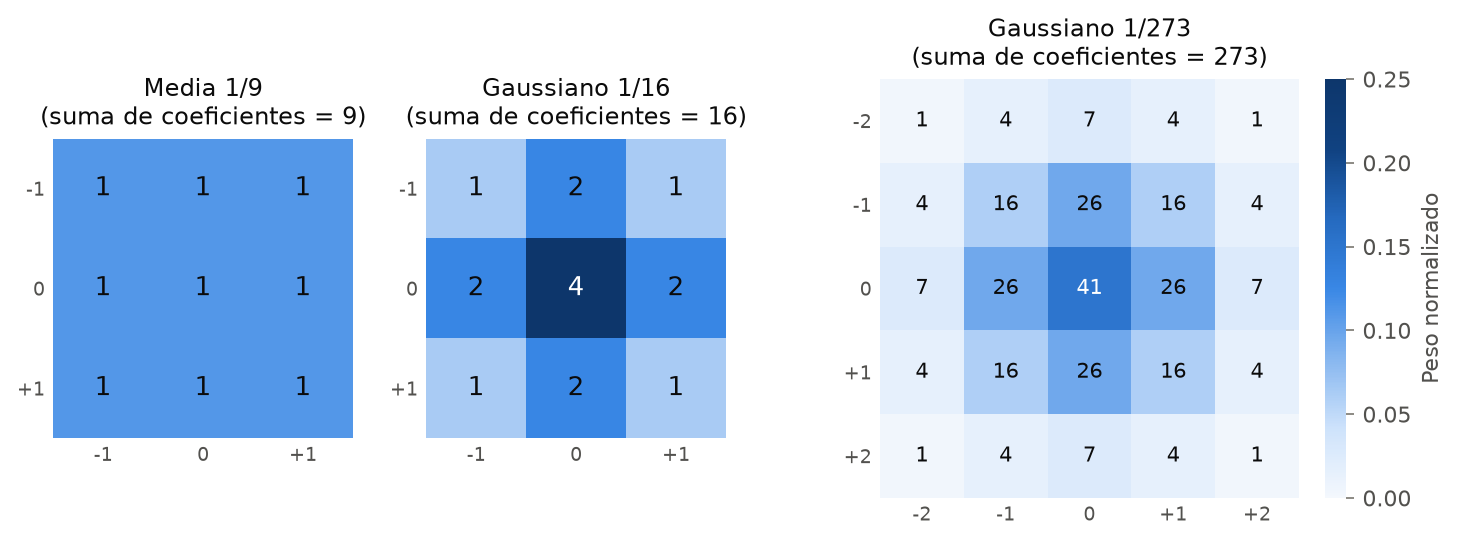

In [2]:
for n in nu.NUCLEOS:
    print(f"{n.nombre}  ({n.lado}×{n.lado}, divisor {n.divisor})")
    print(n.coeficientes, "\n")

ruta = vis.mapas_de_nucleos(nu.NUCLEOS, SALIDAS / "fig01_nucleos.png")
mostrar(ruta)

### 1.1 Propiedades que se leen directamente del núcleo

Tres números resumen el comportamiento de cada núcleo antes de aplicarlo a
ninguna imagen:

- **Peso central.** La fracción del resultado que aporta el propio píxel. En la
  media es 1/9: el píxel central vale lo mismo que cualquier vecino, incluido el
  de la esquina. En los gaussianos el peso decrece con la distancia.
- **Dispersión σ.** La raíz del segundo momento del núcleo, tratado como una
  distribución de probabilidad sobre los desplazamientos. Mide qué tan lejos
  llega el promedio, en píxeles, y es la medida natural del **desenfoque**.
- **Factor de ruido √Σw².** Si a la imagen se le suma un ruido independiente
  entre píxeles con desviación σₙ, el ruido que sale del filtro tiene desviación
  σₙ·√Σw², porque la varianza de una suma ponderada de variables independientes
  es la suma de las varianzas multiplicadas por el cuadrado de los pesos. Mide la
  **capacidad de eliminar ruido**.

La tensión de todo el análisis ya está en estos números: un filtro que elimine
más ruido necesita promediar más píxeles, y promediar más píxeles es exactamente
lo que desenfoca.

In [3]:
print(f"{'':<17}{'lado':>5}{'peso central':>14}{'σ (px)':>9}{'√Σw²':>8}{'mult./píxel':>13}")
print("=" * 66)
propiedades = {}
for n in nu.NUCLEOS:
    p = nu.propiedades(n)
    propiedades[n.nombre] = p
    print(f"{n.nombre:<17}{p['lado']:>5}{p['peso_central']:>14.4f}{p['dispersion']:>9.3f}"
          f"{p['factor_de_ruido']:>8.3f}{p['multiplicaciones_directas']:>13}")

print()
print("Reducción de la desviación del ruido blanco (1 − √Σw²):")
for nombre, p in propiedades.items():
    print(f"  {nombre:<17} {100 * (1 - p['factor_de_ruido']):5.1f} %")

                  lado  peso central   σ (px)    √Σw²  mult./píxel
Media 1/9            3        0.1111    0.816   0.333            9
Gaussiano 1/16       3        0.2500    0.707   0.375            9
Gaussiano 1/273      5        0.1502    0.991   0.277           25

Reducción de la desviación del ruido blanco (1 − √Σw²):
  Media 1/9          66.7 %
  Gaussiano 1/16     62.5 %
  Gaussiano 1/273    72.3 %


El orden no es el mismo en las dos columnas que importan:

- Por **dispersión** (cuánto desenfoca): gaussiano 1/16 < media 1/9 < gaussiano 1/273.
- Por **factor de ruido** (cuánto ruido deja pasar): gaussiano 1/16 > media 1/9 > gaussiano 1/273.

La media ocupa el lugar intermedio en ambas, pero con un matiz. Entre todos los
núcleos 3×3 con pesos que suman 1, **Σw² es mínima cuando todos los pesos son
iguales** —es la desigualdad entre la media aritmética y la cuadrática—. La media
es, por construcción, el núcleo 3×3 que más reduce el ruido blanco. Lo que paga a
cambio no se ve en esta tabla: aparece en la respuesta en frecuencia (sección 3).

### 1.2 Separabilidad

Un núcleo es **separable** si es el producto exterior de un vector columna por un
vector fila. En ese caso filtrar con el núcleo 2-D equivale a filtrar dos veces
con núcleos 1-D —primero en horizontal, después en vertical—, y el costo por
píxel baja de n² a 2n multiplicaciones.

La prueba formal es el rango de la matriz: separable si y sólo si tiene un único
valor singular distinto de cero.

In [4]:
for n in nu.NUCLEOS:
    s = nu.valores_singulares(n)
    columna, fila = nu.factores_separables(n)
    print(f"{n.nombre}")
    print(f"  valores singulares: {np.array2string(s, precision=5, suppress_small=True)}")
    print(f"  energía capturada por la mejor aproximación separable: {100 * nu.energia_de_rango_uno(n):.4f} %")
    if s[1] < 1e-12:
        entero = fila / fila.min()
        print(f"  separable exacto: vector 1-D ∝ {np.round(entero).astype(int)}")
    print()

Media 1/9
  valores singulares: [0.33333 0.      0.     ]
  energía capturada por la mejor aproximación separable: 100.0000 %
  separable exacto: vector 1-D ∝ [1 1 1]

Gaussiano 1/16
  valores singulares: [0.375 0.    0.   ]
  energía capturada por la mejor aproximación separable: 100.0000 %
  separable exacto: vector 1-D ∝ [1 2 1]

Gaussiano 1/273
  valores singulares: [0.27742 0.00351 0.00081 0.      0.     ]
  energía capturada por la mejor aproximación separable: 99.9832 %



La media y el gaussiano 1/16 son separables exactos:

$$\tfrac{1}{9}\begin{bmatrix}1&1&1\\1&1&1\\1&1&1\end{bmatrix} = \tfrac{1}{3}\begin{bmatrix}1\\1\\1\end{bmatrix}\tfrac{1}{3}\begin{bmatrix}1&1&1\end{bmatrix}
\qquad
\tfrac{1}{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix} = \tfrac{1}{4}\begin{bmatrix}1\\2\\1\end{bmatrix}\tfrac{1}{4}\begin{bmatrix}1&2&1\end{bmatrix}$$

El vector [1 2 1] es una fila del triángulo de Pascal: los coeficientes
binomiales, que por el teorema central del límite tienden a una gaussiana al
crecer. El núcleo 1/16 es una gaussiana *exacta en su forma discreta*.

**El gaussiano 1/273 no es separable.** Tiene un segundo valor singular pequeño
pero distinto de cero. La razón es el redondeo: sus coeficientes son una
gaussiana muestreada con σ ≈ 1 y redondeada a enteros, y el redondeo destruye
la factorización. Si fuera separable, su fila central tendría que ser
proporcional a la fila superior, y 7·[1 4 7 4 1] = [7 28 49 28 7] no es
[7 26 41 26 7].

La mejor aproximación separable captura más del 99.98 % de su energía, así que en
la práctica se puede implementar en dos pasadas con un error despreciable; pero
ya no es el mismo núcleo.

In [5]:
for n in (nu.GAUSSIANO_16, nu.GAUSSIANO_273):
    sigma, error = nu.sigma_de_mejor_ajuste(n)
    print(f"{n.nombre}: gaussiana muestreada más cercana σ = {sigma:.3f} "
          f"(máxima diferencia en un peso: {error:.5f})")

# ¿Qué entrega OpenCV cuando se le pide un gaussiano 5×5 sin especificar σ?
g5 = cv2.getGaussianKernel(5, 0)
opencv_5x5 = g5 @ g5.T
print("\ncv2.getGaussianKernel(5, 0) como matriz, escalada a divisor 256:")
print(np.round(opencv_5x5 * 256).astype(int))
print(f"Máxima diferencia contra el núcleo 1/273: "
      f"{np.abs(opencv_5x5 - nu.GAUSSIANO_273.normalizado).max():.5f}")

Gaussiano 1/16: gaussiana muestreada más cercana σ = 0.849 (máxima diferencia en un peso: 0.00013)
Gaussiano 1/273: gaussiana muestreada más cercana σ = 1.048 (máxima diferencia en un peso: 0.00155)

cv2.getGaussianKernel(5, 0) como matriz, escalada a divisor 256:
[[ 1  4  6  4  1]
 [ 4 16 24 16  4]
 [ 6 24 36 24  6]
 [ 4 16 24 16  4]
 [ 1  4  6  4  1]]
Máxima diferencia contra el núcleo 1/273: 0.00956


Dos observaciones útiles para la práctica:

- El núcleo 1/16 coincide con una gaussiana muestreada de σ ≈ 0.85 con un error
  de 10⁻⁴ en los pesos; el 1/273, con una de σ ≈ 1.05 y un error mayor, de 10⁻³.
  Los dos son aproximaciones legítimas a una gaussiana, a escalas distintas.
- `cv2.GaussianBlur` con un tamaño de 5×5 y σ = 0 **no usa el núcleo 1/273**:
  usa el binomial [1 4 6 4 1] ⊗ [1 4 6 4 1] / 256, que es el 1/16 aplicado dos
  veces. Son núcleos parecidos pero no iguales. Quien quiera reproducir el 1/273
  con OpenCV tiene que pasarlo explícitamente a `cv2.filter2D`.

---

## 2. Implementación y verificación

El código de clase nombra a mano los nueve vecinos de un núcleo 3×3
(`arriba_izq`, `arriba`, `arriba_der`, …) y los multiplica uno por uno por los
coeficientes. Para un núcleo 5×5 serían veinticinco variables, así que
`convolucion.filtrar_como_en_clase` recorre el vecindario con dos ciclos más. La
aritmética se conserva sin cambios: productos enteros, suma entera y una sola
división al final con `round` de Python.

Antes de usar cualquier implementación para comparar filtros hay que comprobar
que las tres —la de clase, la vectorizada y la de OpenCV— calculan lo mismo. Si
no coincidieran, una diferencia entre filtros podría venir de la implementación
y no del núcleo.

In [6]:
color = io.cargar(RUTA_FOTO, color=True)
print(io.describir(color, "Archivo original"))
color = io.reducir(color, LADO_MAYOR)
foto = io.a_grises(color)
print(io.describir(foto, "Fotografía de trabajo (gris)"))
alto, ancho = foto.shape

Archivo original: forma=(1024, 768, 3), tipo=uint8, mín=0, máx=255, media=138.27
Fotografía de trabajo (gris): forma=(1024, 768), tipo=uint8, mín=0, máx=255, media=139.89


In [7]:
resultados_clase = {}
tiempo_clase = {}
for n in nu.NUCLEOS:
    t0 = time.perf_counter()
    resultados_clase[n.nombre] = cv.filtrar_como_en_clase(foto, n)
    tiempo_clase[n.nombre] = time.perf_counter() - t0

print(f"{'':<17}{'clase = vectorizado':>21}{'clase = OpenCV (interior)':>28}{'marco negro (px)':>18}")
print("=" * 84)
for n in nu.NUCLEOS:
    clase = resultados_clase[n.nombre]
    vect = cv.filtrar_vectorizado(foto, n)
    opencv = cv.filtrar(foto, n)
    r = n.radio
    iguales_vect = np.array_equal(clase, vect)
    distintos_cv = np.count_nonzero(clase[r:-r, r:-r] != opencv[r:-r, r:-r])
    marco = foto.size - (alto - 2 * r) * (ancho - 2 * r)
    print(f"{n.nombre:<17}{str(iguales_vect):>21}{f'{distintos_cv} píxeles distintos':>28}{marco:>18,}")

                   clase = vectorizado   clase = OpenCV (interior)  marco negro (px)
Media 1/9                         True         0 píxeles distintos             3,580
Gaussiano 1/16                    True         0 píxeles distintos             3,580
Gaussiano 1/273                   True         0 píxeles distintos             7,152


Las tres implementaciones coinciden **bit a bit** en el interior de la imagen.
La única diferencia es el perímetro: la versión de clase no lo evalúa y lo deja
en negro —un marco de un píxel con los núcleos 3×3 y de dos con el 5×5—,
mientras que OpenCV completa el vecindario reflejando la imagen
(`BORDER_REFLECT_101`) y filtra también el borde.

**Un detalle del redondeo.** `round` de Python no redondea «hacia arriba» los
empates: los lleva al entero par más cercano (`round(2.5) = 2`,
`round(3.5) = 4`). Con divisor 9 o 273 un empate es imposible, porque la suma
entera nunca da un cociente con parte fraccionaria exactamente 0.5. Con divisor
16 sí ocurre, cada vez que la suma deja residuo 8. OpenCV redondea los empates
igual, y por eso los resultados coinciden también en esos píxeles.

In [8]:
n = nu.GAUSSIANO_16
suma = sum(int(n.coeficientes[i, j]) * foto[i:alto - 2 + i, j:ancho - 2 + j].astype(np.int64)
           for i in range(3) for j in range(3))
empates = np.count_nonzero(suma % 16 == 8)
print(f"Píxeles del gaussiano 1/16 con empate exacto en la división: {empates:,} "
      f"({100 * empates / suma.size:.2f} % del interior)")

Píxeles del gaussiano 1/16 con empate exacto en la división: 40,259 (5.14 % del interior)


### 2.1 Costo computacional

El número de multiplicaciones por píxel es n²: 9 para los núcleos 3×3 y 25 para
el 5×5, casi el triple. Los núcleos separables bajan a 2n: 6 y, si se aceptara la
aproximación separable del 1/273, 10.

Los tiempos siguientes miden cuatro formas de calcular lo mismo sobre la
fotografía de trabajo. La versión de clase se ejecuta una vez; las demás, varias
veces, y se reporta la mediana.

In [9]:
def cronometrar(funcion, repeticiones):
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        funcion()
        tiempos.append(time.perf_counter() - t0)
    return float(np.median(tiempos))

tiempos = {}
for n in nu.NUCLEOS:
    columna, fila = nu.factores_separables(n)
    tiempos[n.nombre] = {
        "clase": tiempo_clase[n.nombre],
        "vectorizado": cronometrar(lambda: cv.filtrar_vectorizado(foto, n), 10),
        "filter2D": cronometrar(lambda: cv.filtrar(foto, n), 50),
        "separable": cronometrar(lambda: cv.filtrar_separable(foto, columna, fila), 50),
    }

print(f"Fotografía de {ancho}×{alto} = {foto.size:,} píxeles\n")
print(f"{'':<17}{'clase (s)':>11}{'vectorizado (ms)':>18}{'filter2D (ms)':>15}{'separable (ms)':>16}{'clase / filter2D':>18}")
print("=" * 95)
for nombre, t in tiempos.items():
    print(f"{nombre:<17}{t['clase']:>11.2f}{1e3 * t['vectorizado']:>18.2f}{1e3 * t['filter2D']:>15.3f}"
          f"{1e3 * t['separable']:>16.3f}{t['clase'] / t['filter2D']:>18,.0f}×")

Fotografía de 768×1024 = 786,432 píxeles

                   clase (s)  vectorizado (ms)  filter2D (ms)  separable (ms)  clase / filter2D
Media 1/9               0.93              6.99          0.404           0.399             2,301×
Gaussiano 1/16          0.97              6.80          0.404           0.400             2,389×
Gaussiano 1/273         2.38             16.63          1.060           0.554             2,243×


El recorrido explícito en Python es útil para entender la operación y para
verificarla, pero es más de tres órdenes de magnitud más lento que la misma
cuenta ejecutada en código compilado. No es un problema del algoritmo —el número
de multiplicaciones es idéntico— sino del intérprete, que paga el costo de cada
acceso a `img[y, x]` y de cada operación entera por separado.

Entre las versiones compiladas, el 1/273 cuesta del orden de 2.5 veces lo que un
núcleo 3×3, en línea con la razón de 25 a 9 multiplicaciones. Implementarlo en
dos pasadas con su aproximación separable reduce su tiempo casi a la mitad. En
los núcleos 3×3 la versión separable no se distingue de `filter2D` a esta
escala: con tan pocos coeficientes el ahorro de multiplicaciones es marginal.

---

## 3. Respuesta en frecuencia

«Paso bajo» es una afirmación sobre frecuencias: el filtro debe dejar pasar las
variaciones lentas de brillo y atenuar las rápidas. La forma de verificarlo es
calcular la transformada de Fourier del núcleo,

$$H(u,v) = \sum_{x}\sum_{y} w(x,y)\, e^{-i2\pi(ux + vy)}$$

con (u, v) en ciclos por píxel. El intervalo representable va de 0 —brillo
uniforme— a 0.5 ciclos por píxel, la **frecuencia de Nyquist**: un patrón que
alterna claro y oscuro en cada píxel.

Como los tres núcleos son simétricos, w(x, y) = w(−x, −y), la parte imaginaria se
cancela y **H es real**. Ese detalle importa: un valor real negativo no es una
atenuación, es una **inversión de contraste**. La componente de esa frecuencia
sale del filtro con los claros y los oscuros intercambiados. Por eso aquí se
trabaja con H con signo y no con su magnitud |H|, que escondería el fenómeno.

Para la media, el cálculo en una dimensión es inmediato:

$$H(u) = \tfrac{1}{3}\left(e^{i2\pi u} + 1 + e^{-i2\pi u}\right) = \tfrac{1}{3}\bigl(1 + 2\cos 2\pi u\bigr)$$

que vale 1 en u = 0, se anula en u = 1/3 y llega a **−1/3** en Nyquist. Para el
gaussiano 1/16, con el vector [1 2 1]/4:

$$H(u) = \tfrac{1}{4}\bigl(2 + 2\cos 2\pi u\bigr) = \cos^2(\pi u)$$

que decrece de forma monótona de 1 a 0 y **nunca es negativa**.

In [10]:
print(f"{'':<17}{'corte −3 dB':>13}{'corte −3 dB':>13}{'primer cero':>13}{'H(Nyquist)':>12}{'H(Nyquist)':>12}")
print(f"{'':<17}{'horizontal':>13}{'diagonal':>13}{'horizontal':>13}{'horiz.':>12}{'diag.':>12}")
print("=" * 80)
respuesta = {}
for n in nu.NUCLEOS:
    r = fr.resumen(n)
    respuesta[n.nombre] = r
    cero = "—" if np.isnan(r["primer_cero"]) else f"{r['primer_cero']:.3f}"
    print(f"{n.nombre:<17}{r['corte_3db_horizontal']:>13.3f}{r['corte_3db_diagonal']:>13.3f}{cero:>13}"
          f"{r['h_nyquist_horizontal']:>+12.3f}{r['h_nyquist_diagonal']:>+12.3f}")
print("\nFrecuencias en ciclos por píxel. El corte diagonal se mide como frecuencia radial.")

                   corte −3 dB  corte −3 dB  primer cero  H(Nyquist)  H(Nyquist)
                    horizontal     diagonal   horizontal      horiz.       diag.
Media 1/9                0.155        0.159        0.333      -0.333      +0.111
Gaussiano 1/16           0.182        0.185        0.500      +0.000      +0.000
Gaussiano 1/273          0.132        0.133            —      +0.033      +0.004

Frecuencias en ciclos por píxel. El corte diagonal se mide como frecuencia radial.


### 3.1 Verificación experimental con una placa zonal

La respuesta anterior es un cálculo. Para comprobarlo sobre una imagen hace falta
una en la que cada posición tenga una frecuencia conocida: la **placa zonal**,
un patrón de anillos concéntricos cuya frecuencia crece linealmente con la
distancia al centro, de 0 hasta Nyquist en el borde del disco.

Sobre la fila central de la placa, donde la entrada está en un máximo o un
mínimo, el cociente (salida − 128) / (entrada − 128) es la ganancia del filtro
a esa frecuencia, con su signo. Esas mediciones se dibujan como círculos huecos
sobre las curvas teóricas.

Diferencia entre la H medida en la placa y la H teórica:
  Media 1/9         38 puntos, error máximo 0.009, valor medido más negativo -0.322
  Gaussiano 1/16    38 puntos, error máximo 0.008, valor medido más negativo +0.010
  Gaussiano 1/273   38 puntos, error máximo 0.013, valor medido más negativo +0.030


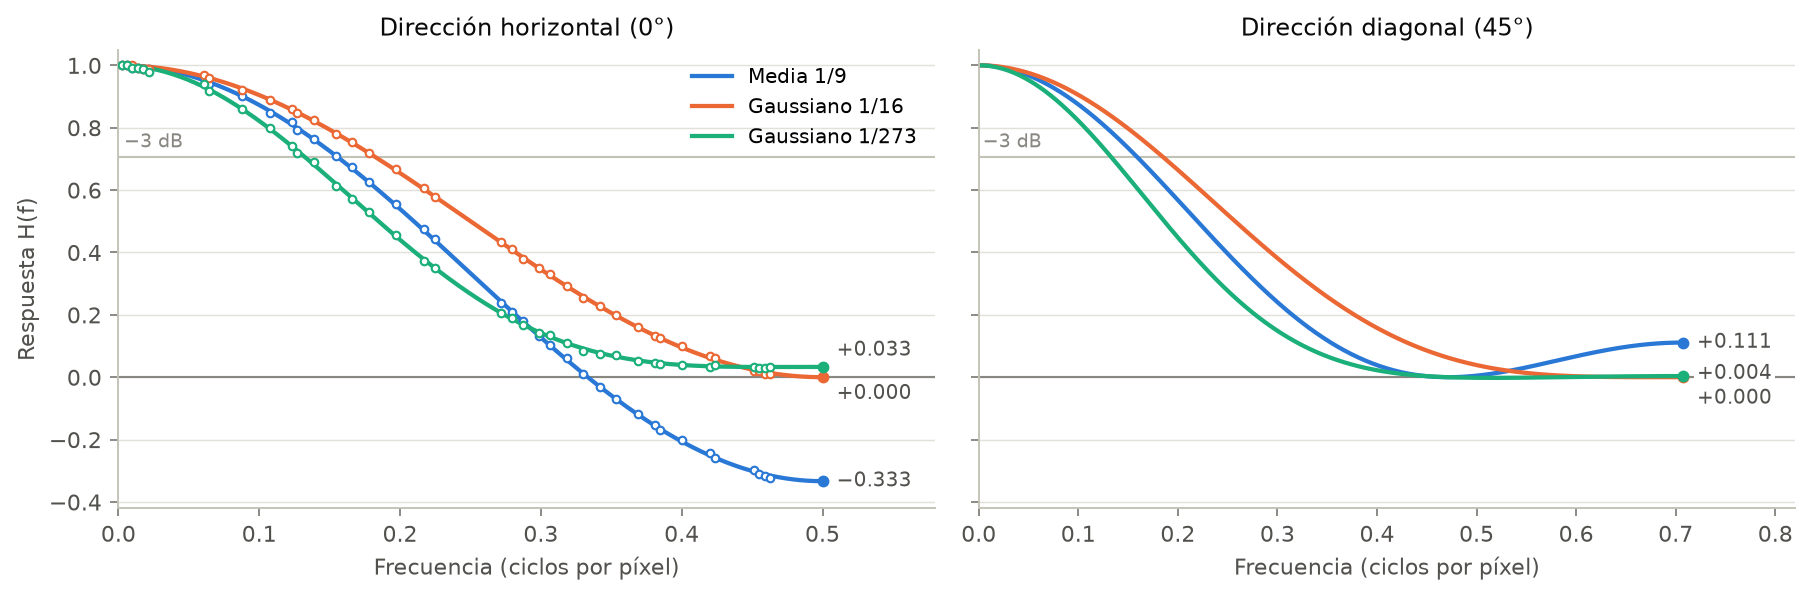

In [11]:
placa = si.placa_zonal(256)
placas_filtradas = {n.nombre: cv.filtrar(placa, n) for n in nu.NUCLEOS}

f_h = np.linspace(0, 0.5, 400)
f_d = np.linspace(0, fr.alcance(45), 400)
PANEL_H, PANEL_D = "Dirección horizontal (0°)", "Dirección diagonal (45°)"

mediciones = {}
print("Diferencia entre la H medida en la placa y la H teórica:")
for n in nu.NUCLEOS:
    f_med, h_med = fr.respuesta_medida_en_placa(placa, placas_filtradas[n.nombre])
    mediciones[n.nombre] = (f_med, h_med)
    error = np.abs(h_med - fr.respuesta_en_direccion(n, f_med, 0.0))
    print(f"  {n.nombre:<17} {f_med.size} puntos, error máximo {error.max():.3f}, "
          f"valor medido más negativo {h_med.min():+.3f}")

ruta = vis.cortes_de_respuesta(
    [(PANEL_H, f_h, {n.nombre: fr.respuesta_en_direccion(n, f_h, 0) for n in nu.NUCLEOS}),
     (PANEL_D, f_d, {n.nombre: fr.respuesta_en_direccion(n, f_d, 45) for n in nu.NUCLEOS})],
    SALIDAS / "fig02_respuesta_en_frecuencia.png",
    desplazamientos={PANEL_H: {"Gaussiano 1/273": 7, "Gaussiano 1/16": -7},
                     PANEL_D: {"Gaussiano 1/273": 1, "Gaussiano 1/16": -9}},
    mediciones={PANEL_H: mediciones},
)
mostrar(ruta)

Las mediciones caen sobre las curvas teóricas con un error de centésimas, que es
el que introduce redondear la salida a enteros. Tres conclusiones se leen en la
figura:

1. **El gaussiano 1/273 es el paso bajo más agresivo**: su corte de −3 dB está en
   la frecuencia más baja. Es la consecuencia en frecuencia de su mayor
   dispersión espacial.
2. **El gaussiano 1/16 es el más conservador**, pero es el único que llega
   exactamente a cero en Nyquist, en las dos direcciones. Elimina por completo el
   patrón de un píxel claro, uno oscuro.
3. **La media cruza el cero en 1/3 de ciclo por píxel y se vuelve negativa.**
   Entre 1/3 y 1/2 de ciclo por píxel no atenúa: invierte. Las mediciones sobre
   la placa lo confirman con valores de hasta −0.33.

El panel diagonal añade una cuarta: la media no se comporta igual en todas las
direcciones. En horizontal termina en −1/3; en diagonal, en +1/9.

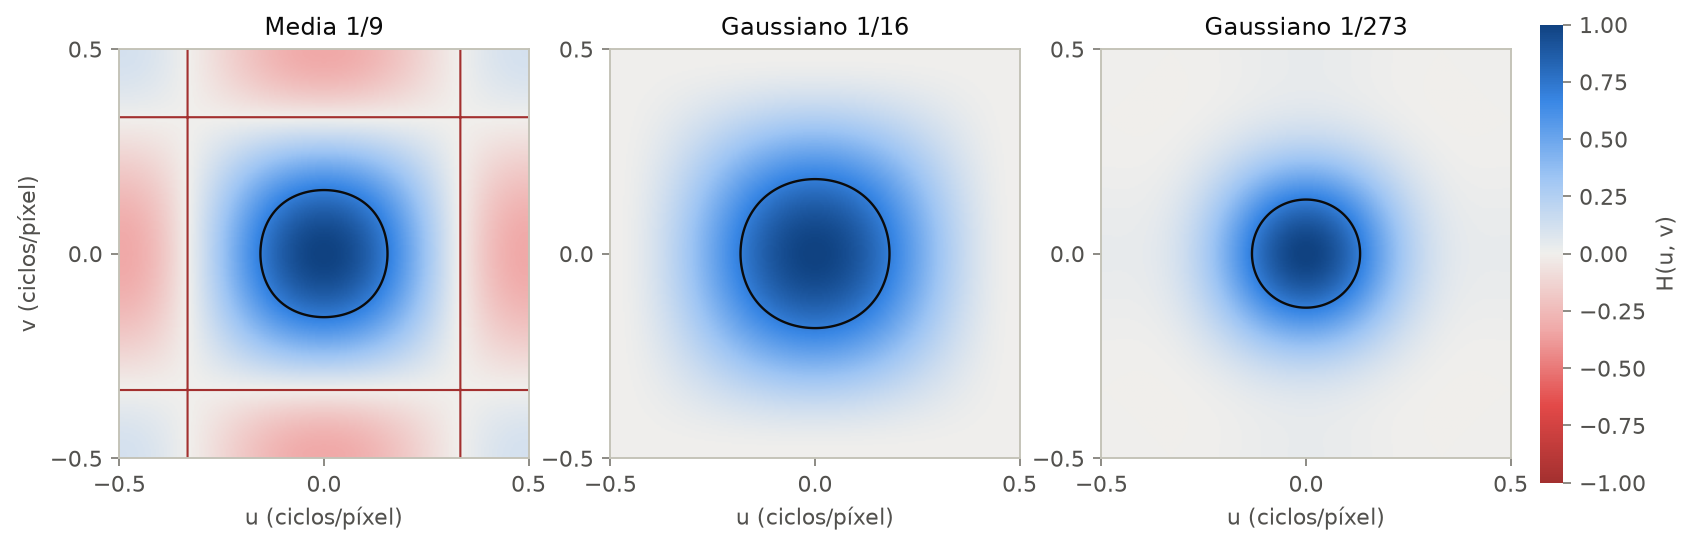

In [12]:
ruta = vis.mapas_de_respuesta([(n.nombre, *fr.respuesta_2d(n)) for n in nu.NUCLEOS],
                              SALIDAS / "fig03_respuesta_2d.png")
mostrar(ruta)

En el plano completo de frecuencias la diferencia es geométrica. Los ceros de la
media forman **un cuadrado** —las rectas u = ±1/3 y v = ±1/3— porque su
respuesta 2-D es el producto (1 + 2cos 2πu)(1 + 2cos 2πv)/9 y se anula cuando
cualquiera de los dos factores lo hace. Fuera de ese cuadrado, en las franjas
rojas, invierte el contraste. El soporte cuadrado del núcleo en el espacio se
traduce en una respuesta con direcciones privilegiadas: el filtro de media es
**anisótropo**.

Los gaussianos, en cambio, tienen contornos casi circulares: tratan igual a un
borde horizontal, a uno vertical y a uno diagonal. Es la propiedad que justifica
su nombre —la gaussiana es la única función separable e isótropa a la vez— y la
razón práctica para preferirlos cuando la orientación de los bordes de la escena
no se conoce de antemano.

El gaussiano 1/273 tiene en las esquinas del plano valores de −0.002, producto
del truncamiento a 5×5 y del redondeo. A ocho bits equivalen a menos de medio
nivel de gris en un patrón de contraste máximo: no son observables y no se
trazan.

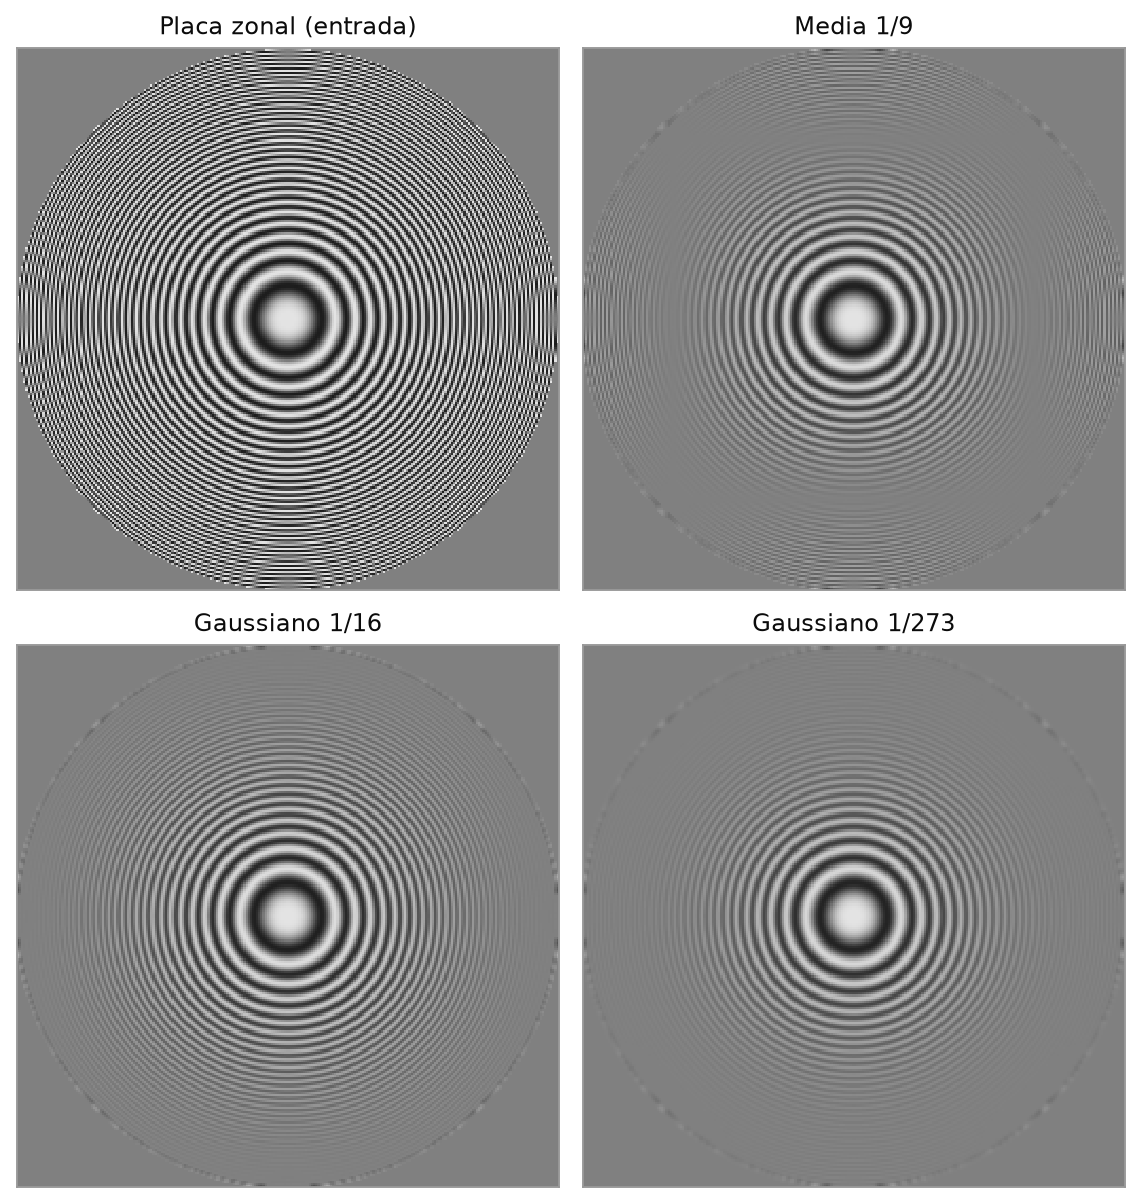

Patrones en la frecuencia de Nyquist (entrada: 60 y 190, contraste ±65 alrededor de 125):

                     franjas verticales    tablero de ajedrez
Media 1/9            147 / 103  (-0.34)    118 / 132  (+0.11)
Gaussiano 1/16       125 / 125  (+0.00)    125 / 125  (+0.00)
Gaussiano 1/273      123 / 127  (+0.03)    125 / 125  (+0.00)

Cada celda: salida en un píxel que era oscuro / uno que era claro (ganancia con signo).


In [13]:
ruta = vis.mosaico([("Placa zonal (entrada)", placa)] + list(placas_filtradas.items()),
                   SALIDAS / "fig04_placa_zonal.png", columnas=2, ancho_panel=3.4)
mostrar(ruta)

print("Patrones en la frecuencia de Nyquist (entrada: 60 y 190, contraste ±65 alrededor de 125):\n")
print(f"{'':<17}{'franjas verticales':>22}{'tablero de ajedrez':>22}")
print("=" * 61)
for n in nu.NUCLEOS:
    celdas = []
    for diagonal in (False, True):
        patron = si.franjas_de_nyquist(64, diagonal=diagonal)
        salida = cv.filtrar(patron, n)[30:34, 30:34].astype(int)
        # Ganancia con signo: la salida en un píxel que en la entrada era oscuro.
        ganancia = round((salida[0, 0] - 125) / (60 - 125), 2) + 0.0  # evita imprimir −0.00
        celdas.append(f"{salida[0, 0]:>3} / {salida[0, 1]:>3}  ({ganancia:+.2f})")
    print(f"{n.nombre:<17}{celdas[0]:>22}{celdas[1]:>22}")
print("\nCada celda: salida en un píxel que era oscuro / uno que era claro (ganancia con signo).")

En la placa zonal, la media borra los anillos cerca de 2/3 del radio —la
frecuencia de 1/3 de ciclo por píxel— y **los hace reaparecer** hacia el borde
con menor contraste: son los anillos invertidos. El gaussiano 1/16 los apaga de
forma gradual hasta el gris uniforme en el borde, y el 1/273 los apaga antes.

La tabla de Nyquist es la versión mínima del mismo experimento. Sobre franjas
verticales de un píxel, la media convierte los píxeles oscuros en claros y
viceversa, con un tercio del contraste original. Ningún gaussiano lo hace. En una
imagen real, eso se traduce en textura fina falsa donde había textura fina
verdadera con la fase contraria.

---

## 4. Efecto sobre una fotografía

Con el comportamiento en frecuencia establecido, se aplican los tres filtros a
una fotografía propia tomada con teléfono. La escena reúne en un solo cuadro los
tipos de contenido que distinguen a un filtro de otro: estructuras periódicas
finas (la rejilla de ventilación, la cortina metálica, los dientes de un cierre),
texto con bordes nítidos, texturas irregulares (cabello, pelaje) y zonas lisas
(la pared).

El archivo mide 768 × 1 024 píxeles, de modo que su lado mayor ya coincide con la
resolución de trabajo y no se escala. Esa resolución importa: a la resolución
nativa del sensor, de varios miles de píxeles por lado, un núcleo de 3×3
abarcaría una fracción ínfima de cualquier estructura y su efecto sería casi
invisible. La imagen se convierte a escala de grises con la ponderación vista en
clase, gris = 0.299R + 0.587G + 0.114B.

Conviene declarar una limitación de la entrada: el archivo es un JPEG, y la
compresión JPEG cuantiza en bloques de 8×8 las frecuencias altas. La fotografía
«limpia» contra la que se miden los filtros ya perdió parte de su detalle más
fino antes de este análisis.

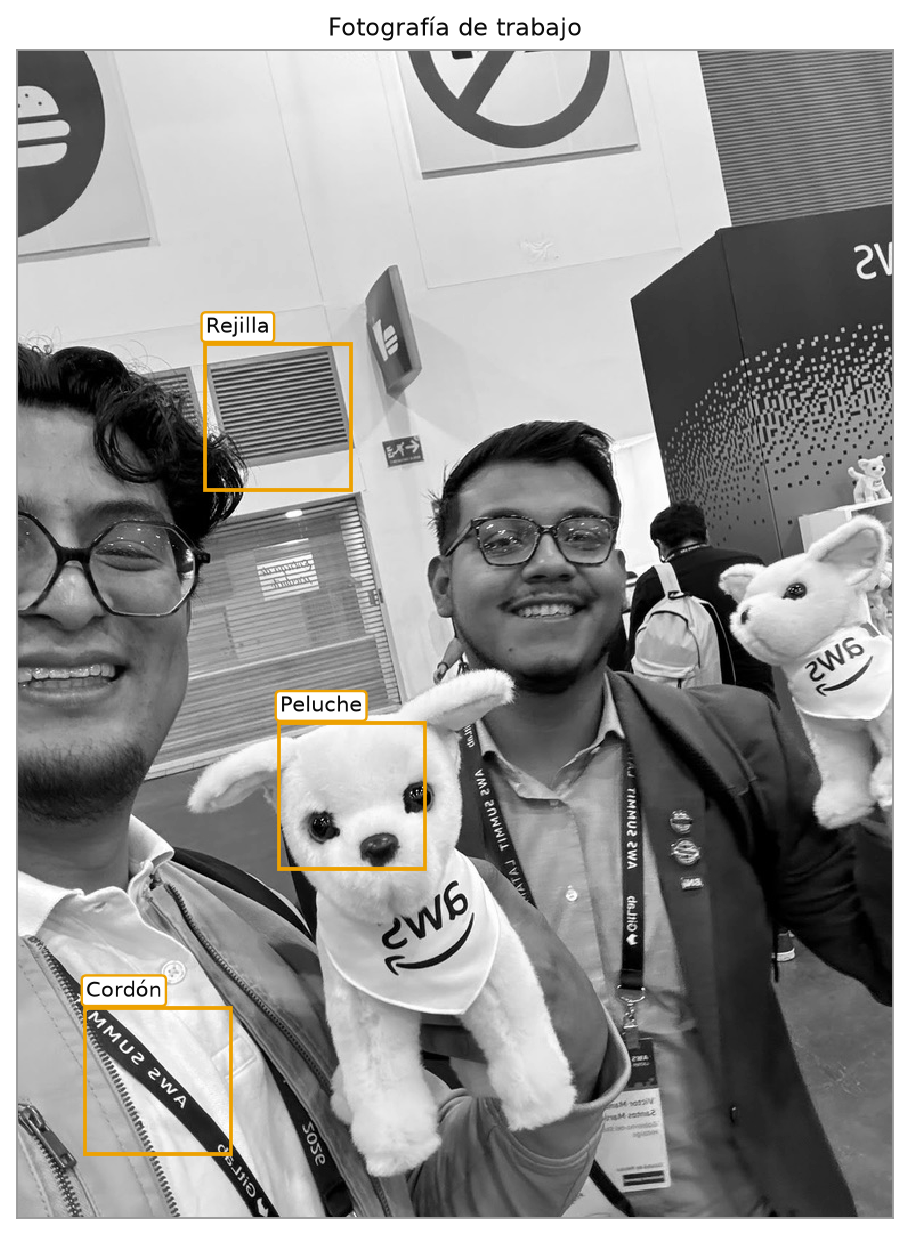

Regiones marcadas: Rejilla, Cordón, Peluche


In [14]:
# Regiones de interés: (x, y, lado) en píxeles de la imagen de trabajo.
REGIONES = {"Rejilla": (165, 258, 128), "Cordón": (60, 840, 128), "Peluche": (230, 590, 128)}
REGION_RUIDO = "Peluche"   # la que se usa para mostrar el efecto del ruido

filtradas = {n.nombre: cv.filtrar(foto, n) for n in nu.NUCLEOS}

def recorte(imagen, region):
    x, y, lado = region
    return imagen[y:y + lado, x:x + lado]

ruta = vis.mosaico([("Fotografía de trabajo", foto)], SALIDAS / "fig05_fotografia.png",
                   ancho_panel=7.0, cajas=[(x, y, l, l) for x, y, l in REGIONES.values()],
                   rotulos_de_cajas=list(REGIONES))
mostrar(ruta)
print("Regiones marcadas:", ", ".join(REGIONES))

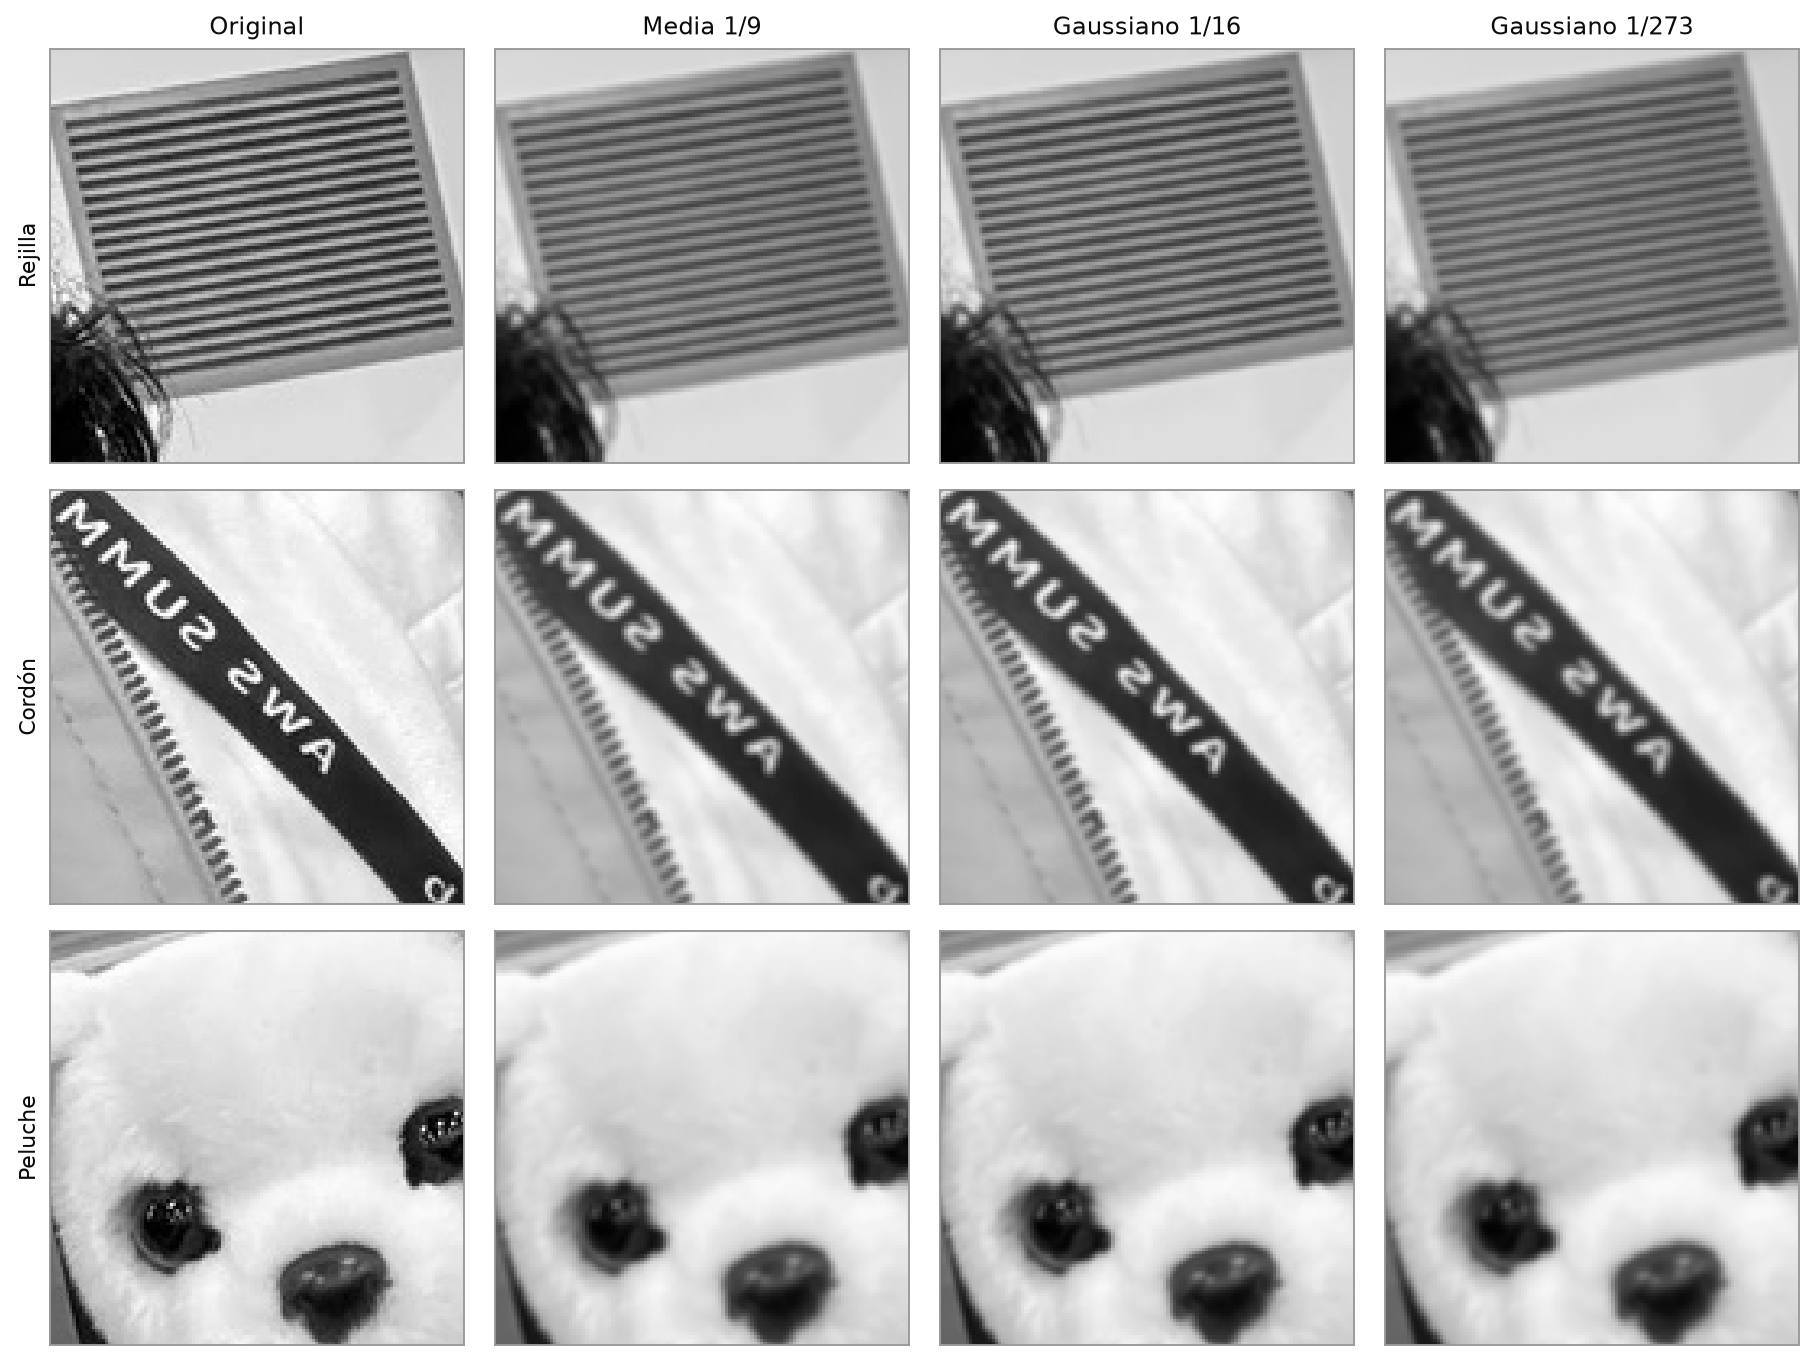

In [15]:
encabezados = ["Original"] + [n.nombre for n in nu.NUCLEOS]
filas = [(nombre, [recorte(foto, region)] + [recorte(filtradas[n.nombre], region) for n in nu.NUCLEOS])
         for nombre, region in REGIONES.items()]
ruta = vis.rejilla_de_ampliaciones(filas, encabezados, SALIDAS / "fig06_ampliaciones.png")
mostrar(ruta)

### 4.1 Lo que cada filtro elimina

La diferencia entre la imagen original y la filtrada es exactamente la parte de
la señal que el filtro no dejó pasar: el **residuo**, que por construcción es la
salida de un filtro paso alto. Mirar el residuo es más revelador que mirar la
imagen filtrada, porque el ojo es mucho mejor detectando la presencia de
estructura que su atenuación.

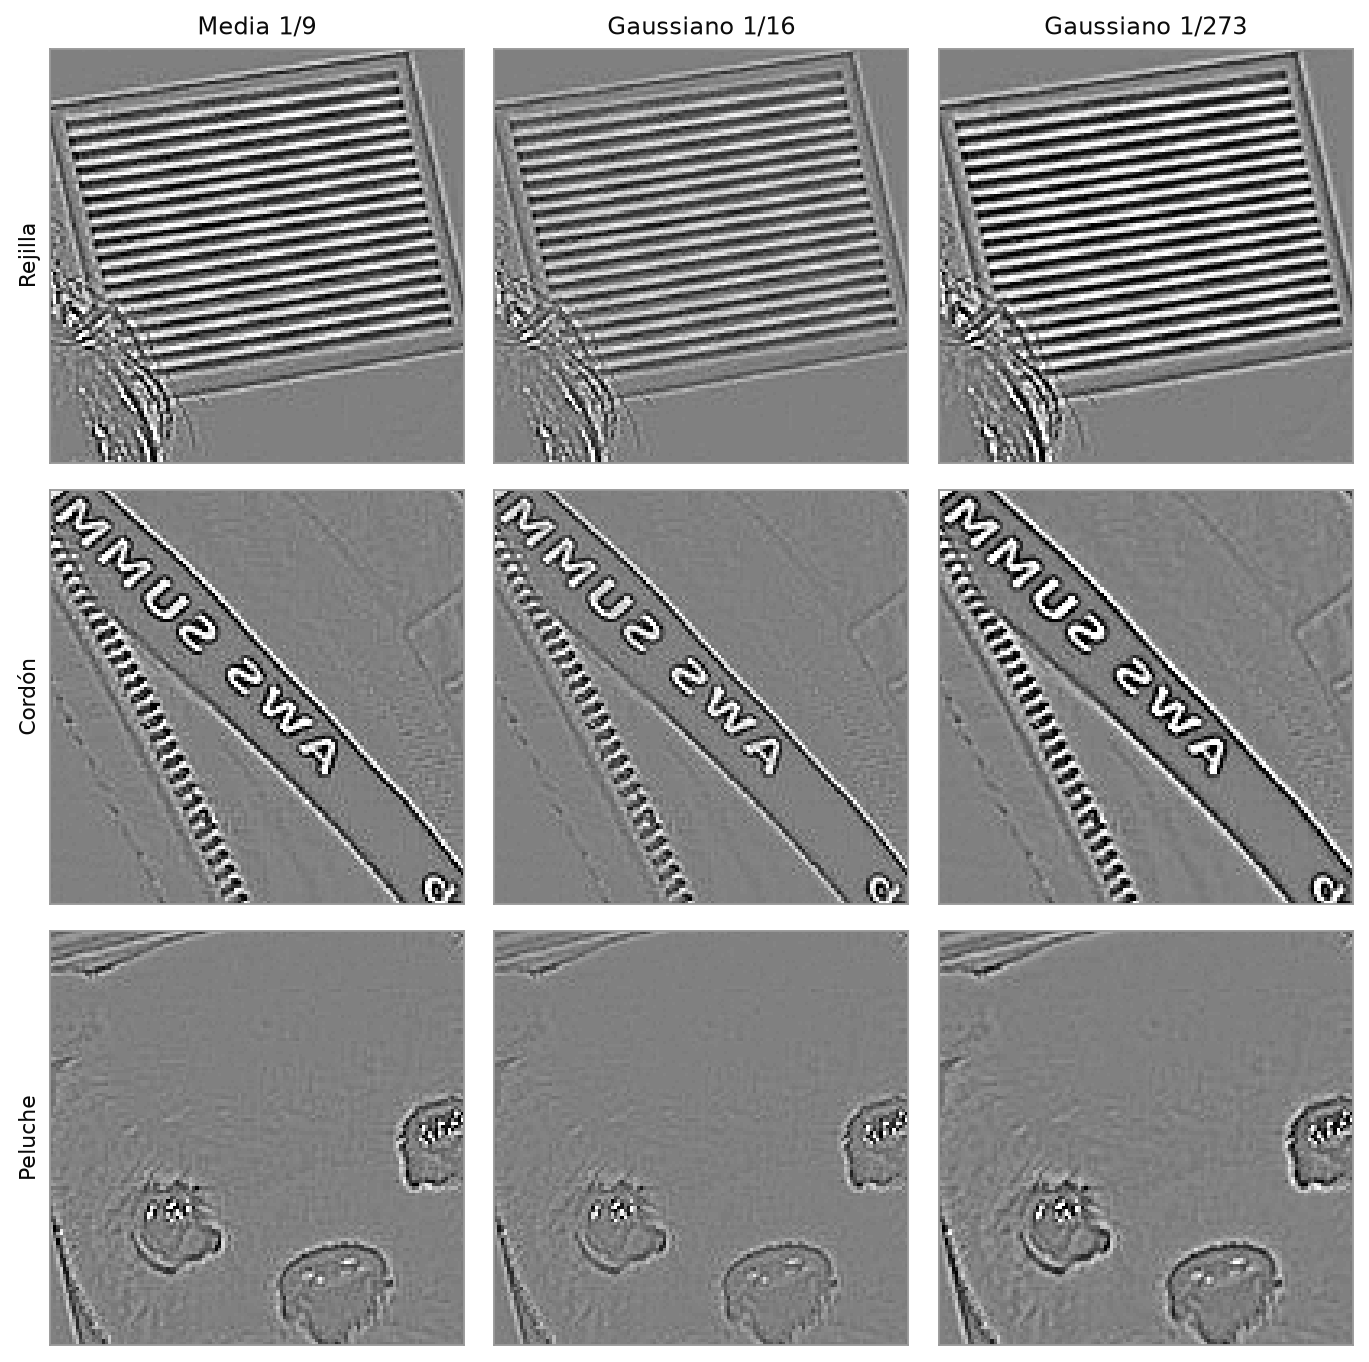

                   RMS del residuo  gradiente conservado  var. laplaciano conservada
Media 1/9                     9.09                 72.3 %                       12.4 %


Gaussiano 1/16                7.09                 78.0 %                       19.3 %
Gaussiano 1/273               9.94                 67.3 %                        8.3 %


In [16]:
residuos = {n.nombre: foto.astype(np.float64) - filtradas[n.nombre].astype(np.float64) for n in nu.NUCLEOS}
filas = [(nombre, [recorte(residuos[n.nombre], region) for n in nu.NUCLEOS]) for nombre, region in REGIONES.items()]
ruta = vis.rejilla_de_ampliaciones(filas, [n.nombre for n in nu.NUCLEOS],
                                   SALIDAS / "fig07_residuos.png", rango=(-40, 40))
mostrar(ruta)

gradiente_0 = me.energia_de_gradiente(foto, MARGEN)
laplaciano_0 = me.varianza_del_laplaciano(foto, MARGEN)
print(f"{'':<17}{'RMS del residuo':>17}{'gradiente conservado':>22}{'var. laplaciano conservada':>28}")
print("=" * 84)
detalle = {}
for n in nu.NUCLEOS:
    g = filtradas[n.nombre]
    detalle[n.nombre] = {
        "rms_residuo": float(np.sqrt(np.mean(me.interior(residuos[n.nombre], MARGEN) ** 2))),
        "gradiente": me.energia_de_gradiente(g, MARGEN) / gradiente_0,
        "laplaciano": me.varianza_del_laplaciano(g, MARGEN) / laplaciano_0,
    }
    d = detalle[n.nombre]
    print(f"{n.nombre:<17}{d['rms_residuo']:>17.2f}{100 * d['gradiente']:>21.1f} %{100 * d['laplaciano']:>27.1f} %")

Las dos métricas de nitidez responden a frecuencias distintas. La energía de
gradiente mide sobre todo el contraste de los **bordes**, y cae de forma
moderada. La varianza del laplaciano responde a la textura **más fina**, cerca de
Nyquist, y cae mucho más: es donde los tres filtros actúan con más fuerza.

El orden de los tres filtros es el mismo en ambas métricas y coincide con el de
la frecuencia de corte de la sección 3: el gaussiano 1/16 conserva más, la media
queda en medio y el 1/273 conserva menos. Las métricas de la imagen confirman lo
que el análisis del núcleo predijo sin mirar la imagen.

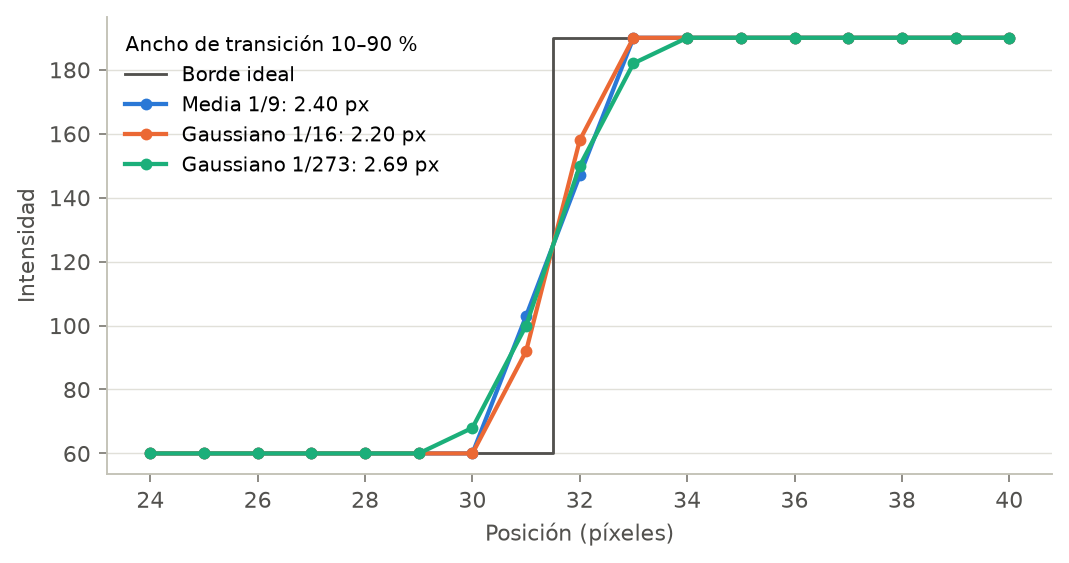

Media 1/9         ancho de transición 10–90 %: 2.40 px
Gaussiano 1/16    ancho de transición 10–90 %: 2.20 px
Gaussiano 1/273   ancho de transición 10–90 %: 2.69 px


In [17]:
escalon = si.escalon(64)
fila = 32
x = np.arange(24, 41)
curvas = {n.nombre: cv.filtrar(escalon, n)[fila, 24:41] for n in nu.NUCLEOS}
anchos = {n.nombre: me.ancho_de_transicion(cv.filtrar_real(escalon, n)[fila, 16:48]) for n in nu.NUCLEOS}
ruta = vis.perfiles(x, escalon[fila, 24:41], curvas, SALIDAS / "fig08_perfil_de_borde.png",
                    etiqueta_referencia="Borde ideal", titulo_de_leyenda="Ancho de transición 10–90 %",
                    rotulos={k: f"{v:.2f} px" for k, v in anchos.items()})
mostrar(ruta)
for nombre, a in anchos.items():
    print(f"{nombre:<17} ancho de transición 10–90 %: {a:.2f} px")

El borde ideal pasa de oscuro a claro entre dos píxeles consecutivos. Cada filtro
lo convierte en una rampa cuyo perfil es la **integral del núcleo** en la
dirección perpendicular al borde. El ancho de transición sigue exactamente el
orden de la dispersión σ de la sección 1: el gaussiano 1/16 deja el borde más
nítido, la media en segundo lugar y el 1/273 el más ancho, porque es el único que
alcanza a dos píxeles de distancia.

---

## 5. Reducción de ruido gaussiano

El ruido gaussiano blanco es el modelo estándar del ruido electrónico de un
sensor: cada píxel recibe una perturbación independiente de media cero. Su
espectro es plano, reparte la misma energía en todas las frecuencias, y por eso
un paso bajo tiene algo que ganar: la mayor parte de la señal útil de una
fotografía está en frecuencias bajas y el ruido está en todas.

### 5.1 Predicción contra medición

La sección 1 predijo que la desviación del ruido a la salida es σₙ·√Σw². Como el
filtro es lineal, filtrar la imagen ruidosa equivale a filtrar por separado la
imagen y el ruido y sumar los resultados. Eso permite aislar el ruido filtrado y
medir su desviación directamente, sin que la imagen interfiera.

In [18]:
SIGMA = 20.0
campo = rd.campo_gaussiano(foto.shape, SIGMA, SEMILLA)
print(f"Ruido de entrada: σ medida = {me.interior(campo, MARGEN).std():.3f} (nominal {SIGMA})\n")
print(f"{'':<17}{'σ predicha':>12}{'σ medida':>11}{'diferencia':>12}")
print("=" * 52)
for n in nu.NUCLEOS:
    predicha = SIGMA * nu.factor_de_ruido(n)
    medida = me.interior(cv.filtrar_real(campo, n), MARGEN).std()
    print(f"{n.nombre:<17}{predicha:>12.3f}{medida:>11.3f}{100 * (medida - predicha) / predicha:>+11.2f} %")

Ruido de entrada: σ medida = 19.990 (nominal 20.0)

                   σ predicha   σ medida  diferencia
Media 1/9               6.667      6.659      -0.11 %
Gaussiano 1/16          7.500      7.486      -0.18 %
Gaussiano 1/273         5.549      5.543      -0.10 %


La predicción se cumple con un error de fracciones de punto porcentual, que es la
variación estadística de una muestra finita de ruido. El factor de ruido no es
una aproximación: es una propiedad exacta de un filtro lineal sobre ruido blanco.

### 5.2 Sobre la fotografía

Ahora el experimento completo: se suma el ruido a la fotografía, se cuantiza a
ocho bits como lo haría una cámara, se filtra, y se compara el resultado con la
fotografía limpia.

                   PSNR (dB)     SSIM
Sin filtrar            22.38   0.3854
Media 1/9              27.08   0.7276
Gaussiano 1/16         27.88   0.7158
Gaussiano 1/273        26.95   0.7720


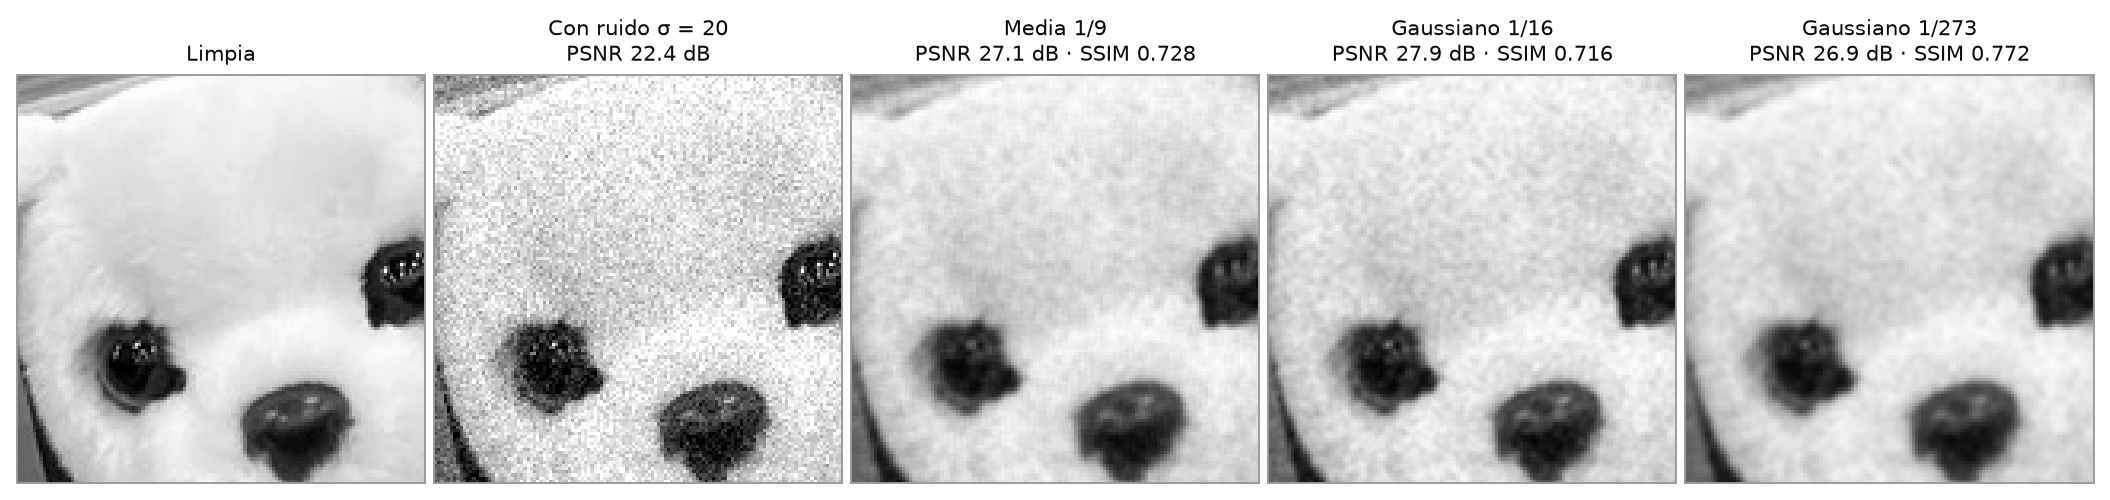

In [19]:
ruidosa = rd.gaussiano(foto, SIGMA, SEMILLA)
limpias = {n.nombre: cv.filtrar(ruidosa, n) for n in nu.NUCLEOS}

print(f"{'':<17}{'PSNR (dB)':>11}{'SSIM':>9}")
print("=" * 37)
calidad_gauss = {"Sin filtrar": (me.psnr(foto, ruidosa, MARGEN), me.ssim(foto, ruidosa, MARGEN))}
for n in nu.NUCLEOS:
    calidad_gauss[n.nombre] = (me.psnr(foto, limpias[n.nombre], MARGEN), me.ssim(foto, limpias[n.nombre], MARGEN))
for nombre, (p, s) in calidad_gauss.items():
    print(f"{nombre:<17}{p:>11.2f}{s:>9.4f}")

region = REGIONES[REGION_RUIDO]
celdas = [[("Limpia", recorte(foto, region)),
           (f"Con ruido σ = {SIGMA:.0f}\nPSNR {calidad_gauss['Sin filtrar'][0]:.1f} dB", recorte(ruidosa, region))]
          + [(f"{n.nombre}\nPSNR {calidad_gauss[n.nombre][0]:.1f} dB · SSIM {calidad_gauss[n.nombre][1]:.3f}",
              recorte(limpias[n.nombre], region)) for n in nu.NUCLEOS]]
ruta = vis.rejilla_con_rotulos(celdas, SALIDAS / "fig09_ruido_gaussiano.png", ancho_panel=2.5)
mostrar(ruta)

### 5.3 Cuando las métricas no coinciden

Con σ = 20 el PSNR y el SSIM no eligen el mismo filtro: por PSNR gana el
gaussiano 1/16 y el 1/273 queda último; por SSIM el orden se invierte. No es un
error de ninguna de las dos, sino una diferencia en **qué ponderan**:

- El PSNR promedia el error **cuadrático** píxel a píxel. Un píxel de borde mal
  reconstruido por 30 niveles pesa lo mismo que 900 píxeles con un error de 1.
  Si el error se concentra en los bordes, el PSNR lo refleja casi por completo.
- El SSIM promedia un índice **por ventana**, y cada ventana pesa lo mismo tenga
  o no estructura. En una fotografía con grandes zonas lisas —la pared, el
  pelaje—, esas ventanas dominan el promedio.

La hipótesis se comprueba separando las ventanas según la desviación estándar
local de la imagen limpia: lisas (σ local < 5) y con estructura (σ local > 20).

In [20]:
m = 7   # margen que descarta ventanas incompletas del SSIM y el perímetro del filtro
d_local = me.interior(me.desviacion_local(foto), m)
lisas, estructura = d_local < 5, d_local > 20
print(f"Ventanas lisas: {100 * lisas.mean():.1f} % de la imagen · con estructura: {100 * estructura.mean():.1f} %\n")
print(f"{'':<17}{'SSIM lisas':>12}{'SSIM estruct.':>15}{'MSE lisas':>12}{'MSE estruct.':>14}{'error en estruct.':>19}")
print("=" * 89)
for n in nu.NUCLEOS:
    g = limpias[n.nombre]
    mapa = me.interior(me.mapa_ssim(foto, g), m)
    e2 = me.interior((g.astype(np.float64) - foto) ** 2, m)
    print(f"{n.nombre:<17}{mapa[lisas].mean():>12.3f}{mapa[estructura].mean():>15.3f}"
          f"{e2[lisas].mean():>12.1f}{e2[estructura].mean():>14.1f}{100 * e2[estructura].sum() / e2.sum():>18.0f} %")

Ventanas lisas: 50.0 % de la imagen · con estructura: 21.6 %

                   SSIM lisas  SSIM estruct.   MSE lisas  MSE estruct.  error en estruct.
Media 1/9               0.668          0.806        44.2         406.7                69 %


Gaussiano 1/16          0.613          0.876        54.7         277.5                56 %
Gaussiano 1/273         0.755          0.776        31.7         466.7                77 %


En las ventanas lisas gana el 1/273, que es el que más ruido elimina; en las
ventanas con estructura gana el 1/16, que es el que menos desenfoca. Las ventanas
con estructura son una fracción minoritaria de la imagen, pero concentran la
mayor parte del error cuadrático. El PSNR queda entonces gobernado por los bordes
y el SSIM por las zonas lisas.

La conclusión práctica es que **la pregunta «¿qué filtro es mejor?» no tiene
respuesta sin decir qué se quiere conservar**. Si el objetivo es que los bordes y
el texto sigan legibles, el 1/16; si es que las superficies uniformes se vean
limpias, el 1/273.

---

## 6. El compromiso entre ruido y detalle

Ningún filtro es el mejor a todos los niveles de ruido, y el motivo se puede
escribir con precisión. Si f es la imagen limpia, n el ruido y w el núcleo, el
error del resultado filtrado se descompone en dos términos:

$$w * (f + n) - f = \underbrace{(w * f - f)}_{\text{desenfoque}} + \underbrace{w * n}_{\text{ruido residual}}$$

Como el ruido es independiente de la imagen, los errores cuadráticos se suman:

$$\text{MSE}_w(\sigma) \approx B_w + \sigma^2 \sum w^2$$

- **B_w** es el error que el filtro comete sobre la imagen limpia: el costo del
  desenfoque. No depende del ruido. Crece con la dispersión del núcleo.
- **σ²Σw²** es el ruido que sobrevive. Crece con el ruido y decrece con el poder
  de promediado del núcleo.

Es la descomposición sesgo–varianza de la estadística, aplicada a un filtro. De
ella se derivan dos predicciones que se pueden verificar:

1. **Filtrar conviene sólo a partir de cierto nivel de ruido.** Sin filtrar, el
   error es σ². El filtro ayuda cuando B_w + σ²Σw² < σ², es decir, a partir de
   $$\sigma^{*} = \sqrt{B_w / (1 - \Sigma w^2)}$$
2. **Entre dos filtros hay un cruce.** El más suave gana con poco ruido —paga
   menos desenfoque— y el más fuerte gana con mucho ruido —elimina más—. Se
   cruzan en
   $$\sigma_{ab} = \sqrt{(B_b - B_a) / (\Sigma w_a^2 - \Sigma w_b^2)}$$

In [21]:
# Término de desenfoque: el error de cada filtro sobre la imagen limpia.
B = {n.nombre: me.mse(foto, filtradas[n.nombre], MARGEN) for n in nu.NUCLEOS}
S = {n.nombre: nu.factor_de_ruido(n) ** 2 for n in nu.NUCLEOS}
print(f"{'':<17}{'B (desenfoque)':>16}{'Σw²':>9}{'σ* predicha':>13}")
print("=" * 55)
for nombre in B:
    print(f"{nombre:<17}{B[nombre]:>16.2f}{S[nombre]:>9.4f}{np.sqrt(B[nombre] / (1 - S[nombre])):>13.2f}")

# Barrido fino del nivel de ruido, la misma semilla en cada nivel.
sigmas = np.arange(0.0, 50.01, 0.5)
psnr_curvas = {"Sin filtrar": []} | {n.nombre: [] for n in nu.NUCLEOS}
mse_curvas = {k: [] for k in psnr_curvas}
for s in sigmas:
    r_img = rd.gaussiano(foto, s, SEMILLA)
    mse_curvas["Sin filtrar"].append(me.mse(foto, r_img, MARGEN))
    for n in nu.NUCLEOS:
        mse_curvas[n.nombre].append(me.mse(foto, cv.filtrar(r_img, n), MARGEN))
mse_curvas = {k: np.array(v) for k, v in mse_curvas.items()}
psnr_curvas = {k: 10 * np.log10(255 ** 2 / np.maximum(v, 1e-12)) for k, v in mse_curvas.items()}

def primer_cruce(x, a, b):
    # Primer x en que la curva a pasa a ser menor que la b (interpolación lineal).
    d = a - b
    i = np.flatnonzero((d[:-1] >= 0) & (d[1:] < 0))
    if i.size == 0:
        return float("nan")
    i = i[0]
    return float(x[i] + (x[i + 1] - x[i]) * d[i] / (d[i] - d[i + 1]))

print("\nNivel de ruido a partir del cual filtrar mejora el PSNR:")
print(f"{'':<17}{'predicho':>10}{'medido':>9}")
for nombre in B:
    predicho = np.sqrt(B[nombre] / (1 - S[nombre]))
    medido = primer_cruce(sigmas, mse_curvas[nombre], mse_curvas["Sin filtrar"])
    print(f"{nombre:<17}{predicho:>10.2f}{medido:>9.2f}")

print("\nCruces entre filtros:")
cruces = {}
for a, b in [("Gaussiano 1/16", "Media 1/9"), ("Gaussiano 1/16", "Gaussiano 1/273"), ("Media 1/9", "Gaussiano 1/273")]:
    # a es el más suave (menor B): gana a la izquierda del cruce.
    suave, fuerte = (a, b) if B[a] < B[b] else (b, a)
    predicho = np.sqrt((B[fuerte] - B[suave]) / (S[suave] - S[fuerte])) if S[suave] > S[fuerte] else float("nan")
    medido = primer_cruce(sigmas, mse_curvas[fuerte], mse_curvas[suave])
    cruces[(suave, fuerte)] = (predicho, medido)
    print(f"  {suave} → {fuerte}: predicho σ = {predicho:.2f}, medido σ = {medido:.2f}")

                   B (desenfoque)      Σw²  σ* predicha
Media 1/9                   82.69   0.1111         9.65
Gaussiano 1/16              50.30   0.1406         7.65
Gaussiano 1/273             98.90   0.0770        10.35



Nivel de ruido a partir del cual filtrar mejora el PSNR:
                   predicho   medido
Media 1/9              9.65     9.78
Gaussiano 1/16         7.65     7.73
Gaussiano 1/273       10.35    10.51

Cruces entre filtros:
  Gaussiano 1/16 → Media 1/9: predicho σ = 33.13, medido σ = 36.28
  Gaussiano 1/16 → Gaussiano 1/273: predicho σ = 27.63, medido σ = 29.77
  Media 1/9 → Gaussiano 1/273: predicho σ = 21.79, medido σ = 23.07


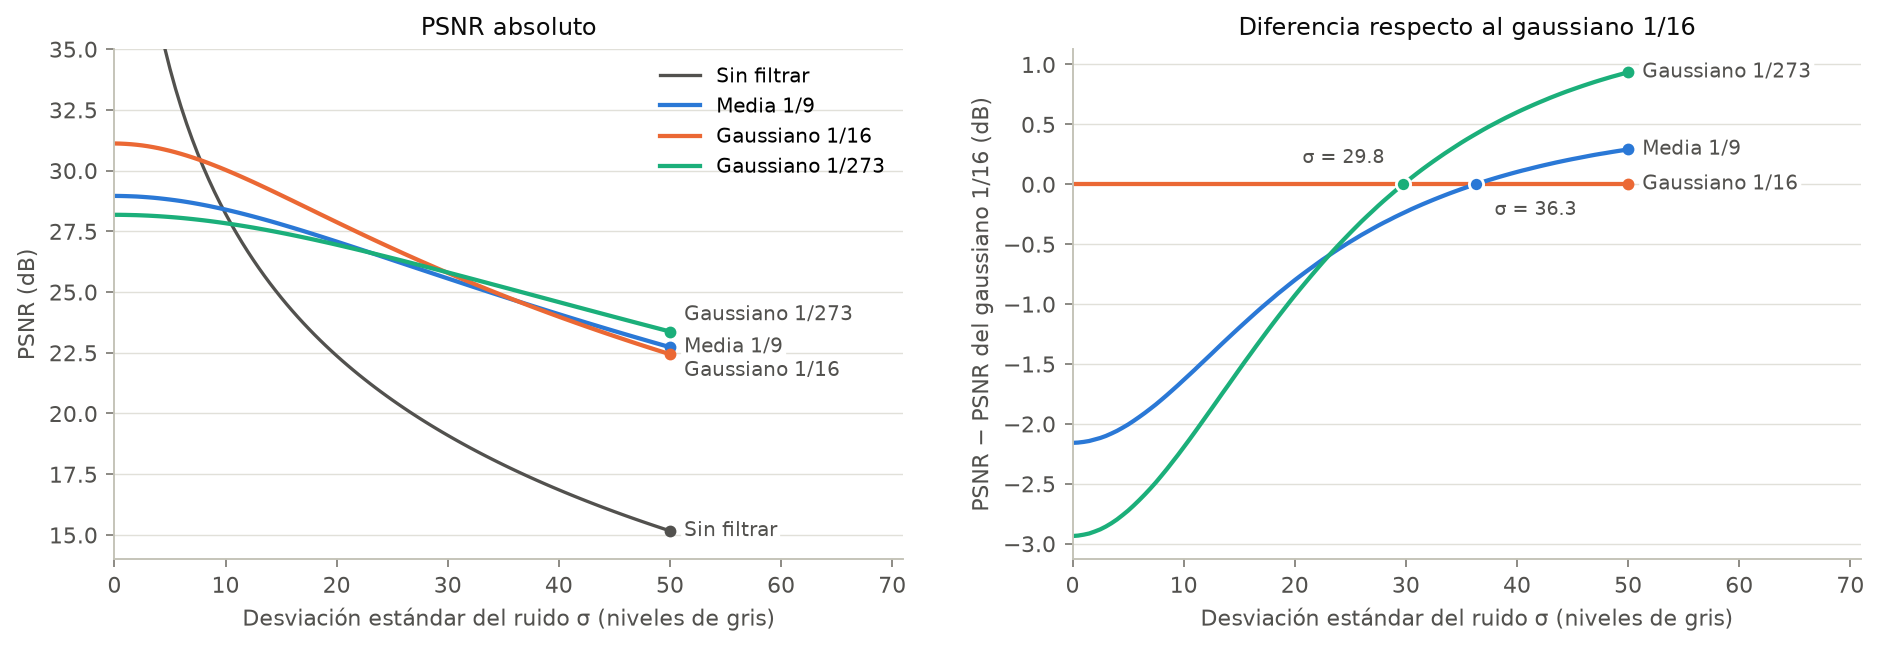

    σ       Sin filtrar         Media 1/9    Gaussiano 1/16   Gaussiano 1/273      mejor filtro
    1             47.80             28.95             31.10             28.17    Gaussiano 1/16
    5             34.19             28.81             30.81             28.09    Gaussiano 1/16
   10             28.23             28.39             30.03             27.83    Gaussiano 1/16
   15             24.77             27.79             28.99             27.44    Gaussiano 1/16
   20             22.38             27.08             27.88             26.95    Gaussiano 1/16
   30             19.10             25.56             25.79             25.81   Gaussiano 1/273
   50             15.17             22.73             22.44             23.37   Gaussiano 1/273

Valores de σ en que la media 1/9 es el mejor filtro: ninguno


In [22]:
ruta = vis.curvas_contra_ruido(
    sigmas, psnr_curvas, referencia="Gaussiano 1/16",
    cruces={"Media 1/9": cruces[("Gaussiano 1/16", "Media 1/9")][1],
            "Gaussiano 1/273": cruces[("Gaussiano 1/16", "Gaussiano 1/273")][1]},
    ruta=SALIDAS / "fig10_psnr_contra_ruido.png",
    desplazamientos={"Gaussiano 1/16": -7, "Gaussiano 1/273": 7, "Media 1/9": 0, "Sin filtrar": 0},
)
mostrar(ruta)

print(f"{'σ':>5}" + "".join(f"{k:>18}" for k in psnr_curvas) + f"{'mejor filtro':>18}")
for s in (1, 5, 10, 15, 20, 30, 50):
    i = int(np.flatnonzero(sigmas == s)[0])
    mejor = max((k for k in psnr_curvas if k != "Sin filtrar"), key=lambda k: psnr_curvas[k][i])
    print(f"{s:>5}" + "".join(f"{psnr_curvas[k][i]:>18.2f}" for k in psnr_curvas) + f"{mejor:>18}")

# ¿Hay algún tramo del barrido en que la media sea el mejor de los tres?
mejor_en_cada_sigma = np.argmax(np.vstack([psnr_curvas[n.nombre] for n in nu.NUCLEOS]), axis=0)
tramo_media = sigmas[mejor_en_cada_sigma == 0]
print("\nValores de σ en que la media 1/9 es el mejor filtro:",
      "ninguno" if tramo_media.size == 0 else f"de {tramo_media.min()} a {tramo_media.max()}")

El umbral a partir del cual conviene filtrar se predice con un error de décimas.
Los cruces entre filtros, en cambio, se observan entre 5 y 10 % más a la derecha
de lo predicho. El modelo omite dos cosas que hace una cámara real: cuantizar a
ocho bits y **recortar** la imagen ruidosa a [0, 255]. En una zona oscura, todo
el ruido que empujaría el valor por debajo de 0 se pierde. El recorte elimina así
parte del ruido antes de filtrar, pero introduce un sesgo que ningún promedio
corrige. Como el recorte afecta a cualquier píxel que esté a menos de unas pocas
σ de los extremos, y esta fotografía tiene amplias zonas oscuras —cabello, saco,
cordón—, su efecto crece con el ruido.

La hipótesis se comprueba repitiendo el barrido sin recorte ni cuantización: la
imagen ruidosa se deja en punto flotante y se filtra con `filtrar_real`.

In [23]:
cerca_de_los_extremos = np.mean((foto <= 30) | (foto >= 225))
print(f"Píxeles a menos de 30 niveles de 0 o de 255: {100 * cerca_de_los_extremos:.1f} %\n")

f_limpia = foto.astype(np.float64)
B_real = {n.nombre: float(np.mean(me.interior(cv.filtrar_real(f_limpia, n) - f_limpia, MARGEN) ** 2)) for n in nu.NUCLEOS}
mse_ideal = {"Sin filtrar": []} | {n.nombre: [] for n in nu.NUCLEOS}
for s in sigmas:
    r_real = f_limpia + rd.campo_gaussiano(foto.shape, s, SEMILLA)
    mse_ideal["Sin filtrar"].append(np.mean(me.interior(r_real - f_limpia, MARGEN) ** 2))
    for n in nu.NUCLEOS:
        mse_ideal[n.nombre].append(np.mean(me.interior(cv.filtrar_real(r_real, n) - f_limpia, MARGEN) ** 2))
mse_ideal = {k: np.array(v) for k, v in mse_ideal.items()}

print(f"{'Cruce':<38}{'predicho':>10}{'medido sin recorte':>20}{'medido con recorte':>20}")
print("=" * 88)
for (suave, fuerte), (predicho, medido) in cruces.items():
    predicho_real = np.sqrt((B_real[fuerte] - B_real[suave]) / (S[suave] - S[fuerte]))
    ideal = primer_cruce(sigmas, mse_ideal[fuerte], mse_ideal[suave])
    print(f"{suave + ' → ' + fuerte:<38}{predicho_real:>10.2f}{ideal:>20.2f}{medido:>20.2f}")

Píxeles a menos de 30 niveles de 0 o de 255: 16.5 %



Cruce                                   predicho  medido sin recorte  medido con recorte
Gaussiano 1/16 → Media 1/9                 33.13               33.22               36.28
Gaussiano 1/16 → Gaussiano 1/273           27.63               27.71               29.77
Media 1/9 → Gaussiano 1/273                21.79               21.87               23.07


Sin recorte, los cruces medidos coinciden con los predichos con un error menor a
una décima. La descomposición sesgo–varianza describe exactamente al filtro
lineal; lo que la aparta de la medición con la imagen cuantizada es la no
linealidad del recorte, no el modelo.

La consecuencia práctica es la conclusión central de la comparación: **la
elección del filtro depende del nivel de ruido esperado**. Con poco ruido, el
gaussiano 1/16 es el mejor porque es el que menos desenfoca; con ruido intenso,
el 1/273 es el mejor porque es el que más promedia. En esta fotografía el cambio
ocurre alrededor de σ = 30, un nivel de ruido muy alto: el ruido de un teléfono
en condiciones normales de luz está muy por debajo. La posición exacta del cruce
depende de la imagen, a través de B_w: una escena con mucho detalle fino —texto,
rejillas— cobra más caro el desenfoque y empuja el cruce hacia la derecha.

La media no es la mejor en ningún tramo del barrido. En todo nivel de ruido existe
un gaussiano que la supera.

---

## 7. Ruido impulsivo: el límite de los tres filtros

El ruido de sal y pimienta sustituye unos pocos píxeles por 0 o 255. No perturba
un poco a todos los píxeles, sino mucho a unos pocos, y la varianza de su error
es enorme. Un promedio no lo elimina: lo reparte entre los vecinos. Un píxel de
255 rodeado de valores cercanos a 100, filtrado con la media, aporta
(255 − 100)/9 ≈ 17 niveles a cada uno de sus nueve vecinos; el impulso se
convierte en una mancha.

Sal y pimienta al 5 % de los píxeles

                   PSNR (dB)     SSIM
Sin filtrar            17.83   0.3765
Media 1/9              24.70   0.6108
Gaussiano 1/16         24.73   0.6062
Gaussiano 1/273        25.09   0.6629


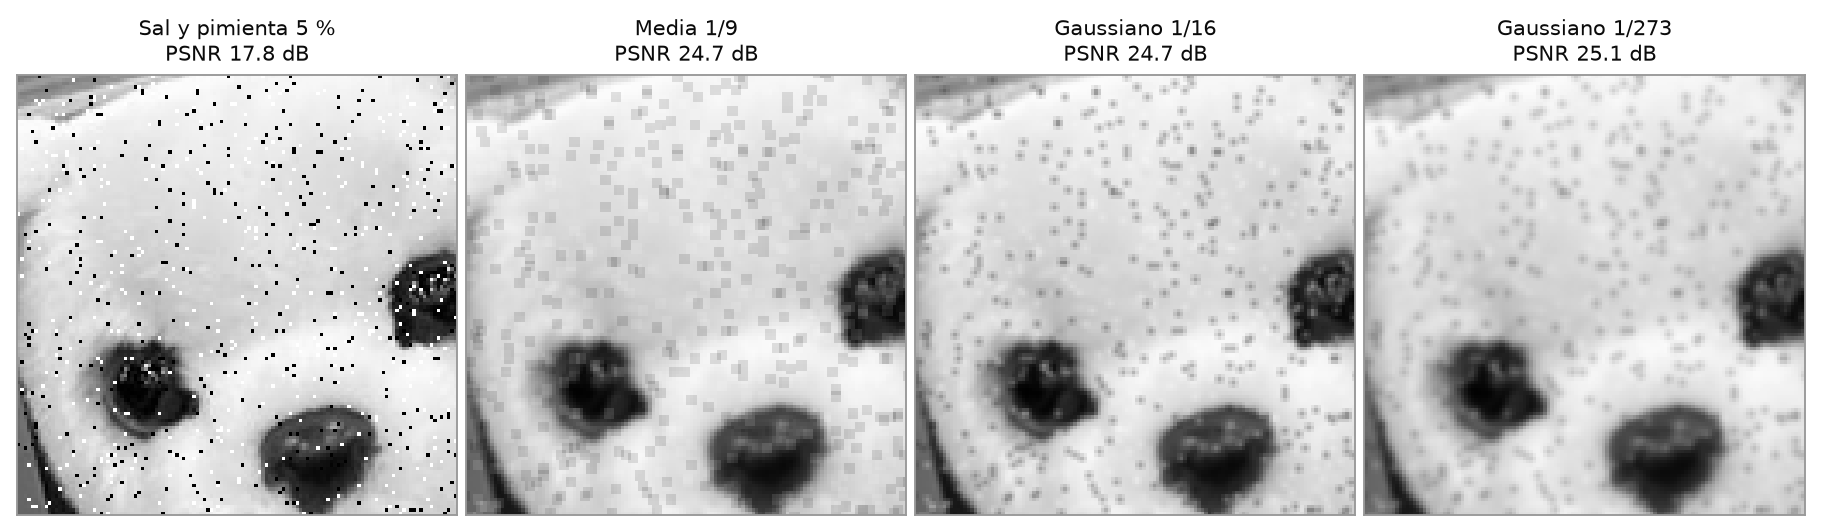

In [24]:
PROPORCION = 0.05
sal = rd.sal_y_pimienta(foto, PROPORCION, SEMILLA)
sal_filtradas = {n.nombre: cv.filtrar(sal, n) for n in nu.NUCLEOS}

calidad_sal = {"Sin filtrar": (me.psnr(foto, sal, MARGEN), me.ssim(foto, sal, MARGEN))}
for n in nu.NUCLEOS:
    calidad_sal[n.nombre] = (me.psnr(foto, sal_filtradas[n.nombre], MARGEN), me.ssim(foto, sal_filtradas[n.nombre], MARGEN))
print(f"Sal y pimienta al {100 * PROPORCION:.0f} % de los píxeles\n")
print(f"{'':<17}{'PSNR (dB)':>11}{'SSIM':>9}")
print("=" * 37)
for nombre, (p, s) in calidad_sal.items():
    print(f"{nombre:<17}{p:>11.2f}{s:>9.4f}")

region = REGIONES[REGION_RUIDO]
celdas = [[(f"Sal y pimienta {100 * PROPORCION:.0f} %\nPSNR {calidad_sal['Sin filtrar'][0]:.1f} dB", recorte(sal, region))]
          + [(f"{n.nombre}\nPSNR {calidad_sal[n.nombre][0]:.1f} dB", recorte(sal_filtradas[n.nombre], region))
             for n in nu.NUCLEOS]]
ruta = vis.rejilla_con_rotulos(celdas, SALIDAS / "fig11_sal_y_pimienta.png", ancho_panel=2.7)
mostrar(ruta)

Los tres filtros mejoran el PSNR —porque reducen la varianza del error— pero
ninguno elimina el ruido. La ampliación muestra por qué: **cada impulso se
convierte en una copia del núcleo**. La respuesta de un filtro lineal a un píxel
aislado es, por definición, el propio núcleo escalado, y eso es lo que se ve:

- con la media, cuadrados de 3×3 de intensidad uniforme;
- con el gaussiano 1/16, un punto concentrado, porque su peso central es el más
  alto (1/4) y deja pasar una cuarta parte del impulso en su propia posición;
- con el 1/273, manchas redondas más tenues, porque reparte el impulso entre
  veinticinco píxeles.

El 1/273 obtiene el mejor PSNR y el mejor SSIM simplemente porque diluye más
cada impulso, no porque lo elimine. Es el límite estructural de cualquier filtro
lineal frente a valores atípicos, y el motivo por el que para este tipo de ruido
se usan filtros no lineales como la mediana, que descarta el valor extremo en
lugar de promediarlo.

---

## 8. Síntesis

La tabla siguiente reúne en un solo lugar los indicadores de las secciones
anteriores.

In [25]:
print(f"{'':<34}" + "".join(f"{n.nombre:>18}" for n in nu.NUCLEOS))
print("=" * 88)
filas = [
    ("Tamaño", lambda n: f"{n.lado}×{n.lado}"),
    ("Peso central", lambda n: f"{propiedades[n.nombre]['peso_central']:.3f}"),
    ("Dispersión σ (px)", lambda n: f"{propiedades[n.nombre]['dispersion']:.3f}"),
    ("Factor de ruido √Σw²", lambda n: f"{propiedades[n.nombre]['factor_de_ruido']:.3f}"),
    ("Separable", lambda n: "Sí" if nu.energia_de_rango_uno(n) > 1 - 1e-12 else "No (99.98 %)"),
    ("Corte −3 dB (ciclos/px)", lambda n: f"{respuesta[n.nombre]['corte_3db_horizontal']:.3f}"),
    ("H en Nyquist (horizontal)", lambda n: f"{respuesta[n.nombre]['h_nyquist_horizontal']:+.3f}"),
    ("Invierte contraste", lambda n: "Sí" if respuesta[n.nombre]['h_minimo'] < -0.01 else "No"),
    ("Ancho de borde 10–90 % (px)", lambda n: f"{anchos[n.nombre]:.2f}"),
    ("Gradiente conservado", lambda n: f"{100 * detalle[n.nombre]['gradiente']:.1f} %"),
    ("PSNR, ruido σ = 20 (dB)", lambda n: f"{calidad_gauss[n.nombre][0]:.2f}"),
    ("SSIM, ruido σ = 20", lambda n: f"{calidad_gauss[n.nombre][1]:.4f}"),
    ("PSNR, sal y pimienta 5 % (dB)", lambda n: f"{calidad_sal[n.nombre][0]:.2f}"),
    ("filter2D (ms)", lambda n: f"{1e3 * tiempos[n.nombre]['filter2D']:.3f}"),
]
for rotulo, valor in filas:
    print(f"{rotulo:<34}" + "".join(f"{valor(n):>18}" for n in nu.NUCLEOS))

                                           Media 1/9    Gaussiano 1/16   Gaussiano 1/273
Tamaño                                           3×3               3×3               5×5
Peso central                                   0.111             0.250             0.150
Dispersión σ (px)                              0.816             0.707             0.991
Factor de ruido √Σw²                           0.333             0.375             0.277
Separable                                         Sí                Sí      No (99.98 %)
Corte −3 dB (ciclos/px)                        0.155             0.182             0.132
H en Nyquist (horizontal)                     -0.333            +0.000            +0.033
Invierte contraste                                Sí                No                No
Ancho de borde 10–90 % (px)                     2.40              2.20              2.69
Gradiente conservado                          72.3 %            78.0 %            67.3 %
PSNR, ruido σ = 20 (d

**Media 1/9.** Es el núcleo 3×3 que más reduce el ruido blanco, y tiene una
ventaja de implementación que los gaussianos no tienen: al ser todos sus pesos
iguales, puede calcularse con sumas acumuladas en tiempo constante por píxel sin
importar el tamaño del núcleo. A cambio, invierte el contraste de las frecuencias
entre 1/3 y 1/2 de ciclo por píxel y trata distinto a los bordes según su
orientación. En el barrido de ruido no es el mejor en ningún tramo.

**Gaussiano 1/16.** Es el que mejor conserva el detalle: el borde más nítido, el
corte de frecuencia más alto y la mayor energía de gradiente conservada. Es
separable, isótropo en la práctica y el único que anula exactamente la
frecuencia de Nyquist. En esta fotografía es el mejor por PSNR hasta niveles de
ruido muy altos, y el mejor en las ventanas con estructura.

**Gaussiano 1/273.** Es el que más ruido elimina y el que más desenfoca. Cuesta
casi el triple de multiplicaciones por píxel y, por el redondeo de sus
coeficientes, deja de ser separable exactamente. Es el mejor en las zonas lisas,
por SSIM, y el mejor por PSNR cuando el ruido es intenso.

Ninguno de los tres sirve contra ruido impulsivo.